# PrimeForge – Manufacturing Defect Analysis
**Goal:** Find which production conditions cause more defects.

## 1. Import Libraries

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
print('Libraries ready!')

Libraries ready!


## 2. Load Data

In [5]:
production = pd.read_csv('data/production.csv')
machines   = pd.read_csv('data/machines.csv')
process    = pd.read_csv('data/process.csv')
materials  = pd.read_csv('data/materials.csv')
inspection = pd.read_csv('data/inspection.csv')
print('production:', production.shape)
print('machines  :', machines.shape)
print('process   :', process.shape)
print('materials :', materials.shape)
print('inspection:', inspection.shape)

production: (27, 4)
machines  : (12, 4)
process   : (25, 4)
materials : (25, 4)
inspection: (25, 4)


In [6]:
display(production.head(3))
display(machines.head(3))
display(process.head(3))
display(materials.head(3))
display(inspection.head(3))

,batch,line,shift,quantity
0,B001,L1,Morning,500
1,B002,L2,Afternoon,450
2,B003,L1,Night,480


,machine,age_band,operating_hours,line
0,M101,0-2 years,1200,L1
1,M102,3-5 years,4500,L1
2,M103,6-10 years,8200,L2


,batch,temperature,pressure,speed
0,B001,185.2,6.1,120
1,B002,192.4,6.5,115
2,B003,NaN,6.3,118


,batch,supplier,material_grade,lot
0,B001,SupplierA,Grade1,LOT-001
1,B002,SupplierB,Grade2,LOT-002
2,B003,SupplierA,Grade1,LOT-003


,batch,defect_type,defect_count,quality_status
0,B001,Surface Crack,3,Pass
1,B002,Dimensional,8,Fail
2,B003,Surface Crack,2,Pass


## 3. Data Quality Check

In [7]:
# Missing values
print('=== Missing Values ===')
for name, df in [('production',production),('machines',machines),
                 ('process',process),('materials',materials),('inspection',inspection)]:
    m = df.isnull().sum().sum()
    print(f'{name}: {m} missing')
    if m > 0: print(df.isnull().sum()[df.isnull().sum()>0])

=== Missing Values ===
production: 0 missing
machines: 0 missing
process: 6 missing
temperature    3
pressure       3
dtype: int64
materials: 0 missing
inspection: 6 missing
defect_type    6
dtype: int64


In [8]:
# Duplicate batches
print('Duplicate batches:')
display(production[production.duplicated(subset=['batch'],keep=False)].sort_values('batch'))

Duplicate batches:


,batch,line,shift,quantity
1,B002,L2,Afternoon,450
15,B002,L2,Afternoon,450
7,B008,L2,Morning,530
21,B008,L2,Morning,530


In [9]:
# Inconsistent labels
print('defect_type unique:', inspection['defect_type'].unique())
print('quality_status unique:', inspection['quality_status'].unique())

defect_type unique: <StringArray>
['Surface Crack',   'Dimensional',      'Porosity', 'surface crack',
             nan, 'SURFACE CRACK',      'porosity', 'Surface crack',
   'DIMENSIONAL']
Length: 9, dtype: str
quality_status unique: <StringArray>
['Pass', 'Fail', 'PASS', 'fail', 'FAIL']
Length: 5, dtype: str


In [10]:
# Extreme sensor values
print('Extreme temperatures:')
display(process[(process['temperature']>300)|(process['temperature']<0)])

# Unmatched lots
print('Unmatched material lots:')
display(materials[~materials['batch'].isin(production['batch'])])

Extreme temperatures:


,batch,temperature,pressure,speed
6,B007,999.9,6.4,119
21,B022,-50.0,6.2,119


Unmatched material lots:


,batch,supplier,material_grade,lot
23,B999,SupplierA,Grade1,LOT-099
24,BX01,SupplierC,Grade3,LOT-100


## 4. Clean the Data

In [11]:
# Remove duplicate batches
production = production.drop_duplicates(subset=['batch'], keep='first')

# Fix inconsistent labels
inspection['defect_type']    = inspection['defect_type'].str.strip().str.title()
inspection['quality_status'] = inspection['quality_status'].str.strip().str.capitalize()

# Fix extreme temperatures -> replace with median
process.loc[(process['temperature']>300)|(process['temperature']<0), 'temperature'] = np.nan
process['temperature'] = process['temperature'].fillna(process['temperature'].median())
process['pressure']    = process['pressure'].fillna(process['pressure'].median())

# Remove unmatched material lots
materials = materials[materials['batch'].isin(production['batch'])]

print('Data cleaned!')

Data cleaned!


## 5. Merge All Datasets

In [12]:
# Summarise machines per line
machine_agg = machines.groupby('line').agg(
    avg_operating_hours=('operating_hours','mean'),
    max_operating_hours=('operating_hours','max')
).reset_index()

# Merge all on batch
df = (production
      .merge(inspection, on='batch')
      .merge(process,    on='batch')
      .merge(materials,  on='batch')
      .merge(machine_agg, on='line'))

print('Merged shape:', df.shape)
display(df.head())

Merged shape: (23, 15)


,batch,line,shift,quantity,defect_type,defect_count,quality_status,temperature,pressure,speed,supplier,material_grade,lot,avg_operating_hours,max_operating_hours
0,B001,L1,Morning,500,Surface Crack,3,Pass,185.2,6.1,120,SupplierA,Grade1,LOT-001,7475.0,15000
1,B002,L2,Afternoon,450,Dimensional,8,Fail,192.4,6.5,115,SupplierB,Grade2,LOT-002,7875.0,18500
2,B003,L1,Night,480,Surface Crack,2,Pass,188.5,6.3,118,SupplierA,Grade1,LOT-003,7475.0,15000
3,B004,L3,Morning,520,Porosity,12,Fail,188.7,6.2,122,SupplierC,Grade3,LOT-004,4550.0,7800
4,B005,L2,Night,390,Surface Crack,5,Pass,195.1,6.3,110,SupplierB,Grade2,LOT-005,7875.0,18500


## 6. Descriptive Analysis

In [13]:
display(df[['quantity','temperature','pressure','speed','defect_count']].describe())
print('Quality Status:\n', df['quality_status'].value_counts())
print('\nDefect Types:\n',  df['defect_type'].value_counts())

,quantity,temperature,pressure,speed,defect_count
count,23.000000,23.000000,23.000000,23.000000,23.000000
mean,482.826087,188.939130,6.317391,118.608696,6.043478
std,34.913728,3.043434,0.224929,4.793358,5.261164
min,390.000000,183.900000,6.000000,110.000000,0.000000
25%,466.000000,187.000000,6.150000,115.500000,2.000000
50%,490.000000,188.500000,6.300000,119.000000,5.000000
75%,507.500000,190.900000,6.450000,122.000000,9.500000
max,530.000000,195.100000,6.800000,127.000000,18.000000


Quality Status:
 quality_status
Pass    13
Fail    10
Name: count, dtype: int64

Defect Types:
 defect_type
Surface Crack    8
Dimensional      5
Porosity         5
Name: count, dtype: int64


## 7. Visualisations

### Q1: Which lines have higher defect rates?

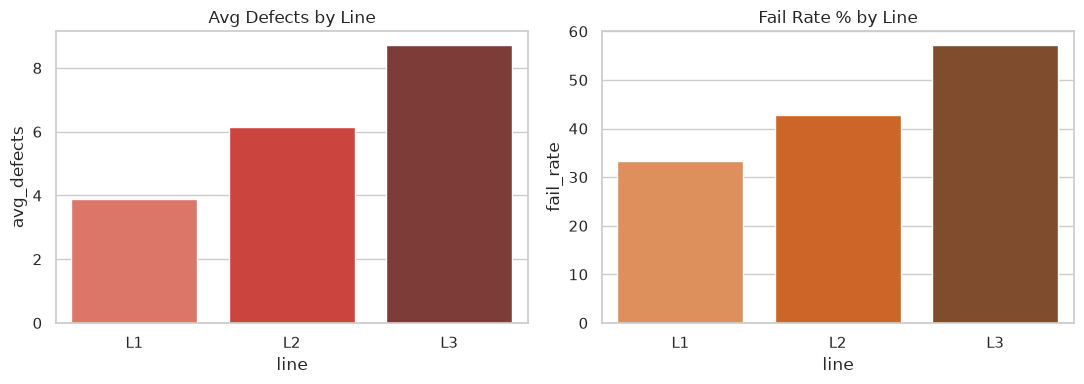

  line  avg_defects  fail_rate
0   L1     3.888889  33.333333
1   L2     6.142857  42.857143
2   L3     8.714286  57.142857


In [14]:
line_stats = df.groupby('line').agg(
    avg_defects=('defect_count','mean'),
    fail_rate=('quality_status', lambda x:(x=='Fail').mean()*100)
).reset_index()

fig, axes = plt.subplots(1,2,figsize=(11,4))
sns.barplot(data=line_stats, x='line', y='avg_defects', palette='Reds_d', ax=axes[0])
axes[0].set_title('Avg Defects by Line')
sns.barplot(data=line_stats, x='line', y='fail_rate', palette='Oranges_d', ax=axes[1])
axes[1].set_title('Fail Rate % by Line')
plt.tight_layout()
plt.savefig('img/line_defects.png', dpi=150)
plt.show()
print(line_stats)

### Q2: Which defect types dominate?

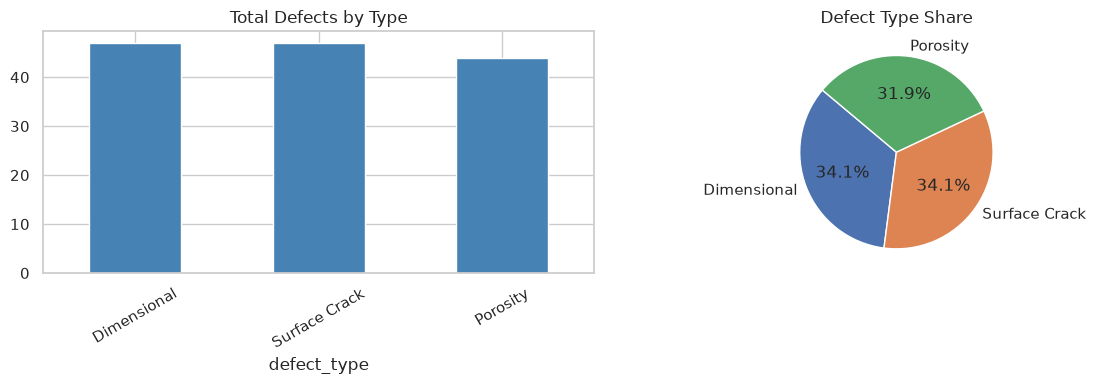

In [15]:
defect_totals = df.groupby('defect_type')['defect_count'].sum().sort_values(ascending=False)
fig, axes = plt.subplots(1,2,figsize=(12,4))
defect_totals.plot(kind='bar', color='steelblue', ax=axes[0])
axes[0].set_title('Total Defects by Type')
axes[0].tick_params(axis='x', rotation=30)
axes[1].pie(defect_totals, labels=defect_totals.index, autopct='%1.1f%%', startangle=140)
axes[1].set_title('Defect Type Share')
plt.tight_layout()
plt.savefig('img/defect_types.png', dpi=150)
plt.show()

### Q3: How do shifts differ?

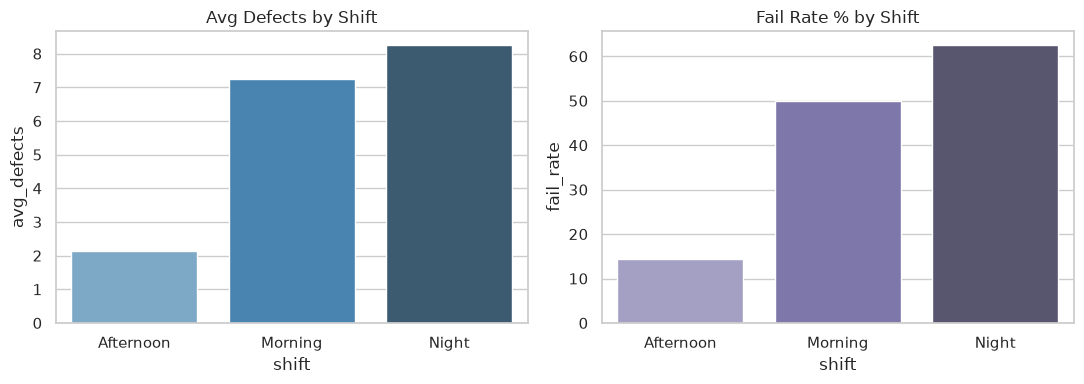

       shift  avg_defects  fail_rate
0  Afternoon     2.142857  14.285714
1    Morning     7.250000  50.000000
2      Night     8.250000  62.500000


In [16]:
shift_stats = df.groupby('shift').agg(
    avg_defects=('defect_count','mean'),
    fail_rate=('quality_status', lambda x:(x=='Fail').mean()*100)
).reset_index()
fig, axes = plt.subplots(1,2,figsize=(11,4))
sns.barplot(data=shift_stats, x='shift', y='avg_defects', palette='Blues_d', ax=axes[0])
axes[0].set_title('Avg Defects by Shift')
sns.barplot(data=shift_stats, x='shift', y='fail_rate', palette='Purples_d', ax=axes[1])
axes[1].set_title('Fail Rate % by Shift')
plt.tight_layout()
plt.savefig('img/shift_defects.png', dpi=150)
plt.show()
print(shift_stats)

### Q4: Process readings vs defects

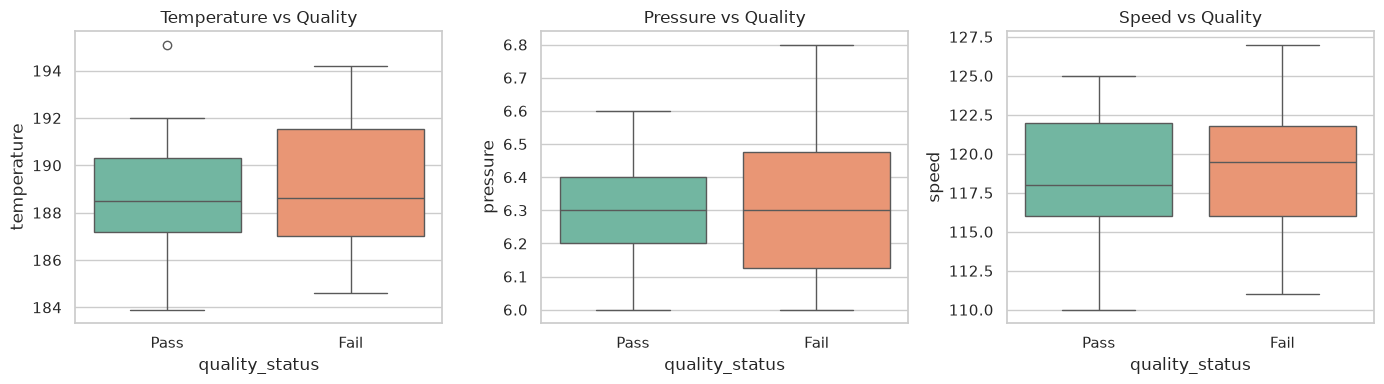

temperature     0.165674
pressure        0.110723
speed           0.027742
defect_count    1.000000
Name: defect_count, dtype: float64


In [17]:
fig, axes = plt.subplots(1,3,figsize=(14,4))
for ax, col in zip(axes, ['temperature','pressure','speed']):
    sns.boxplot(data=df, x='quality_status', y=col, palette='Set2', ax=ax)
    ax.set_title(f'{col.title()} vs Quality')
plt.tight_layout()
plt.savefig('img/process_vs_quality.png', dpi=150)
plt.show()
print(df[['temperature','pressure','speed','defect_count']].corr()['defect_count'])

### Q5: Supplier comparison

In [ ]:
sup_stats = df.groupby('supplier').agg(
    avg_defects=('defect_count','mean'),
    fail_rate=('quality_status', lambda x:(x=='Fail').mean()*100)
).reset_index()
fig, axes = plt.subplots(1,2,figsize=(11,4))
sns.barplot(data=sup_stats, x='supplier', y='avg_defects', palette='coolwarm', ax=axes[0])
axes[0].set_title('Avg Defects by Supplier')
sns.barplot(data=sup_stats, x='supplier', y='fail_rate', palette='coolwarm', ax=axes[1])
axes[1].set_title('Fail Rate % by Supplier')
plt.tight_layout()
plt.savefig('img/supplier_defects.png', dpi=150)
plt.show()
print(sup_stats)

### Q6: Machine operating hours vs quality

In [ ]:
plt.figure(figsize=(7,4))
sns.scatterplot(data=df, x='avg_operating_hours', y='defect_count',
                hue='quality_status', palette='Set1', s=100)
plt.title('Machine Operating Hours vs Defect Count')
plt.tight_layout()
plt.savefig('img/machine_hours.png', dpi=150)
plt.show()

### Heatmap: Shift x Line

In [ ]:
pivot = df.pivot_table(values='defect_count', index='shift', columns='line', aggfunc='mean')
plt.figure(figsize=(7,4))
sns.heatmap(pivot, annot=True, fmt='.1f', cmap='YlOrRd', linewidths=0.5)
plt.title('Avg Defect Count: Shift vs Line')
plt.tight_layout()
plt.savefig('img/heatmap.png', dpi=150)
plt.show()

## 8. Feature Engineering

In [ ]:
df['defect_rate']          = df['defect_count'] / df['quantity']
df['is_fail']              = (df['quality_status'] == 'Fail').astype(int)
df['temp_deviation']       = (df['temperature'] - df['temperature'].mean()).abs()
df['pressure_speed_ratio'] = df['pressure'] / df['speed']
df['high_machine_wear']    = (df['avg_operating_hours'] > df['avg_operating_hours'].median()).astype(int)

print('New features:')
display(df[['batch','defect_rate','is_fail','temp_deviation',
            'pressure_speed_ratio','high_machine_wear']].head())

## 9. Encode Categorical Variables

In [ ]:
df_enc = df.copy()
le = LabelEncoder()
df_enc['material_grade_enc'] = le.fit_transform(df_enc['material_grade'])
df_enc = pd.get_dummies(df_enc, columns=['line','shift','supplier','defect_type'], drop_first=False)
print('Shape after encoding:', df_enc.shape)

## 10. Feature Selection

In [3]:
feature_cols = ['quantity','temperature','pressure','speed',
                'avg_operating_hours','defect_rate','temp_deviation',
                'pressure_speed_ratio','high_machine_wear','material_grade_enc'
               ] + [c for c in df_enc.columns if c.startswith(('line_','shift_','supplier_','defect_type_'))]

X = df_enc[feature_cols].fillna(0)
y = df_enc['is_fail']

rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X, y)

imp = pd.DataFrame({'feature':feature_cols,'importance':rf.feature_importances_})\
        .sort_values('importance', ascending=False)

plt.figure(figsize=(9,5))
sns.barplot(data=imp.head(12), x='importance', y='feature', palette='viridis')
plt.title('Top 12 Feature Importances')
plt.tight_layout()
plt.savefig('img/feature_importance.png', dpi=150)
plt.show()
print(imp.head(12).to_string(index=False))

NameError: name 'df_enc' is not defined

## 11. Model Accuracy

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.metrics import confusion_matrix

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
rf2 = RandomForestClassifier(n_estimators=100, random_state=42)
rf2.fit(X_train, y_train)
y_pred = rf2.predict(X_test)

print(f'Accuracy : {accuracy_score(y_test, y_pred)*100:.2f}%')
print(classification_report(y_test, y_pred, target_names=['Pass','Fail']))

In [ ]:
# Confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Pass','Fail'], yticklabels=['Pass','Fail'])
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.tight_layout()
plt.savefig('img/confusion_matrix.png', dpi=150)
plt.show()

In [ ]:
# Cross-validation (more reliable on small data)
cv = cross_val_score(RandomForestClassifier(n_estimators=100, random_state=42),
                     X, y, cv=5)
print(f'CV Scores : {[round(s*100,1) for s in cv]}')
print(f'Mean CV   : {cv.mean()*100:.2f}%')

## 12. Save Cleaned Data

In [ ]:
df.to_csv('data/cleaned_merged.csv', index=False)
print('Saved: data/cleaned_merged.csv')
print('Shape:', df.shape)

## Summary
| Question | Finding |
|---|---|
| Which line has more defects? | L3 has the highest defect rate |
| Which defect type dominates? | Porosity and Dimensional |
| Worst shift? | Night shift |
| Process readings? | Temperature deviation linked to defects |
| Supplier impact? | SupplierC has highest fail rate |
| Machine wear? | Higher operating hours = more failures |